In [7]:
# Metadados
__author__ = "Luidy"
__version__ = "3.0.0 - Versão Test"
__status__ = "Otimizado com GridSearch, Teste de Friedman e SHAP"

# Bibliotecas Padrão
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Algoritmos de Machine Learning e Baseline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

# Ferramentas de Treino, Validação e Estatística
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.inspection import permutation_importance 
from sklearn.preprocessing import StandardScaler
from scipy.stats import friedmanchisquare

# Métricas
from sklearn.metrics import (
    confusion_matrix, 
    make_scorer, 
    ConfusionMatrixDisplay, 
    recall_score,           
    accuracy_score,          
    classification_report,
    roc_curve,                
    roc_auc_score,            
    precision_recall_curve,   
    average_precision_score   
)

# Explicabilidade
import shap

# Configurações Visuais
sns.set(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

# Inicializar JS do SHAP no Notebook
shap.initjs()

In [8]:
# Funções básicas para melhor visualização e impressão
def linha(tamanho = 60):
    print("_"*tamanho)

def dimensoes(dataframe, opcao):
    match opcao:
        case 0:
            print(f"Dimensões atuais do dataframe: {dataframe.shape}")
            linha()
        case 1:
            print(f"Dimensões atuais do dataframe: {dataframe.shape}")
            linha()
            display(dataframe.head())
        case _:
            print("Opção invalida. Sintaxe (dataframe, opção [0 ou 1])")

# Função de carregamento de dataset
def carregar_dataset(caminho):
    linha(90)
    print("INICIANDO CARREGAMENTO DE DATASET")
    print(f"Buscando arquivo {caminho}...")

    try:
        print("Arquivo encontrado! Carregando dataset...")
        df_sujo = pd.read_csv(caminho, low_memory=False)
        print("Arquivo bruto carregado")
        dimensoes(df_sujo, 1)
        return df_sujo
    except FileNotFoundError:
        print(f"Arquivo {caminho} não encontrado. Certifique-se de que o nome está correto.")
        return None
    except Exception as error:
        print(f"Erro desconhecido: {error}")
        return None

In [9]:
def filtrar_colunas(dataframe):
    mapa_colunas={
        'label': 'Target',           
        'C-424144002': 'Idade', 
        'C-263495000': 'Genero', 
        'C-72166-2': 'Fumo',
        'C-9279-1': 'Freq_Respiratoria', 
        'C-8867-4': 'Freq_Cardiaca', 
        'C-8480-6': 'Pressao_Sistolica', 
        'C-8462-4': 'Pressao_Diastolica',
        'C-267036007': 'Falta_Ar', 
        'C-66857006': 'Tosse_Sangue', 
        'C-39156-5': 'IMC', 
        'C-2708-6': 'Sat_Oxigenio', 
        'C-49727002': 'Tosse', 
        'C-84229001': 'Fadiga', 
        'C-7200002': 'Alcoolismo', 
        'C-56018004': 'Chiado'
    }
    print("Filtrando Colunas...")
    linha()
    colunas_existentes = [c for c in mapa_colunas.keys() if c in dataframe.columns]
    df = dataframe[colunas_existentes].rename(columns=mapa_colunas)
    dimensoes(df, 0)
    return df
    
def tratar_dados(dataframe):
    print("Tratando valores booleanos...")
    linha()
    booleanos = ['Falta_Ar', 'Tosse_Sangue', 'Tosse', 'Fadiga', 'Alcoolismo', 'Chiado']
    for c in booleanos:
        if c in dataframe.columns:
            dataframe[c] = dataframe[c].fillna(0).astype(str).replace({
                'True':1, "1":1, "1.0":1, 'False':0, '0':0, "0.0":0
            })
            dataframe[c] = pd.to_numeric(dataframe[c], errors='coerce').fillna(0).astype(int)
            
    print("Tratando valores categóricos...")
    linha()
    categoricos = ['Freq_Respiratoria', 'Freq_Cardiaca', 'Pressao_Sistolica', 'Pressao_Diastolica']
    for c in categoricos:
        if c in dataframe.columns:
            dataframe[c] = dataframe[c].fillna('normal')

    if "Fumo" in dataframe.columns:
        dataframe["Fumo"] = dataframe["Fumo"].fillna("fumante_ativo").replace({
            "never":"não_fumante", "former":"ex_fumante"
        })
    if "Idade" in dataframe.columns:
        dataframe['Idade'] = dataframe['Idade'].replace({
            "50t70":"50_a_70_anos", "gt70":"Mais_de_70", "30t50":"30_a_50_anos"
        })
    
    print("Verificando e apagando duplicatas...")
    duplicatas = dataframe.duplicated().sum()
    print(f'{duplicatas} duplicatas encontradas e removidas.')
    linha()
    dataframe = dataframe.drop_duplicates()
    
    print("Criando dummies...")
    linha()
    dataframe = pd.get_dummies(dataframe, drop_first=True)
    dataframe = dataframe.replace({True: 1, False: 0})

    print("Dados tratados com sucesso!")
    dimensoes(dataframe, 1)
    return dataframe

In [10]:
def preparar_dados_treino(dataframe, classe):
    if dataframe is None:
        print("O dataframe não foi enviado.")
        return None
        
    print("Preparando o ambiente para treino dos modelos")
    x = dataframe.drop(columns=classe)
    y = dataframe[classe]
    
    x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.3, stratify=y, random_state=42)

    # Prevenção de Data Leakage: Scaler ajustado apenas no treino
    scaler = StandardScaler()
    x_treino_scaled = scaler.fit_transform(x_treino)
    x_treino = pd.DataFrame(x_treino_scaled, columns=x.columns, index=x_treino.index)

    x_teste_scaled = scaler.transform(x_teste)
    x_teste = pd.DataFrame(x_teste_scaled, columns=x.columns, index=x_teste.index)

    print(f"   -> Treino: {x_treino.shape}")
    print(f"   -> Teste:  {x_teste.shape}")
    linha()
    
    # Modelos instanciados puros (Hiperparâmetros serão definidos pelo GridSearch)
    algoritmos = {
        "Baseline (Dummy)":    DummyClassifier(random_state=42),
        "Regressão Logística": LogisticRegression(class_weight='balanced', random_state=42),
        "Árvore de Decisão":   DecisionTreeClassifier(class_weight='balanced', random_state=42),
        "Random Forest":       RandomForestClassifier(class_weight='balanced', random_state=42),
        "SVM (Support Vector)": SVC(probability=True, class_weight='balanced', random_state=42),
        "Gradient Boosting":   GradientBoostingClassifier(random_state=42)
    }

    return x_treino, x_teste, y_treino, y_teste, algoritmos

def otimizar_e_comparar_algoritmos(x_treino, y_treino, algoritmos):
    print("Iniciando Busca de Hiperparâmetros e Validação Cruzada Múltipla...")
    print("Critério 1: Recall (foco primário da otimização)")
    print("Critério 2: Especificidade (desempate com margem de 1%)")
    linha()
    
    param_grids = {
        "Baseline (Dummy)": {'strategy': ['stratified', 'most_frequent']},
        "Regressão Logística": {'C': [0.01, 0.1, 1, 10], 'solver': ['liblinear']},
        "Árvore de Decisão": {'max_depth': [None, 5, 10], 'min_samples_split': [2, 5]},
        "Random Forest": {'n_estimators': [50, 100], 'max_depth': [None, 10]},
        "SVM (Support Vector)": {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},
        "Gradient Boosting": {'n_estimators': [50, 100], 'learning_rate': [0.01, 0.1]}
    }

    # O scorer que estava faltando
    scorer = {
        'recall': 'recall',
        'especificidade': make_scorer(recall_score, pos_label=0)
    }
    
    kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    resultados = []
    resultados_recall_folds = {}
    melhores_modelos = {}

    # Atualizando o cabeçalho para acomodar o tamanho dos desvios
    print(f"{'MODELO':<22} | {'RECALL (± DESVIO)':^18} | {'ESPECIF. (± DESVIO)':^20} | {'HIPERPARÂMETROS'}")
    linha()
    
    for nome, modelo in algoritmos.items():
        grid = GridSearchCV(modelo, param_grids[nome], cv=kfold, scoring=scorer, refit='recall', n_jobs=-1)
        grid.fit(x_treino, y_treino)
        
        melhores_modelos[nome] = grid.best_estimator_
        best_index = grid.best_index_
        
        # Extraindo médias e desvios
        media_recall = grid.cv_results_['mean_test_recall'][best_index]
        desvio_recall = grid.cv_results_['std_test_recall'][best_index]
        min_recall = media_recall - desvio_recall
        
        media_espec = grid.cv_results_['mean_test_especificidade'][best_index]
        desvio_espec = grid.cv_results_['std_test_especificidade'][best_index]
        min_espec = media_espec - desvio_espec
        
        # Coletar scores dos folds para o Teste de Friedman
        folds_scores = [grid.cv_results_[f'split{i}_test_recall'][best_index] for i in range(5)]
        resultados_recall_folds[nome] = folds_scores
        
        resultados.append({
            'Modelo': nome,
            'Recall': media_recall,
            'Min.Recall': min_recall,
            'Especificidade': media_espec,
            'Min.Especificidade': min_espec,
            'Objeto': grid.best_estimator_
        })
        
        # Formatando as strings com Média ± Desvio para exibição
        str_recall = f"{media_recall:.2%} ± {desvio_recall:.2%}"
        str_espec = f"{media_espec:.2%} ± {desvio_espec:.2%}"
        
        print(f"{nome:<22} | {str_recall:^18} | {str_espec:^20} | {grid.best_params_}")

    linha()
    
    # Lógica de Desempate baseada no Min.Recall
    podio = pd.DataFrame(resultados).sort_values(by='Min.Recall', ascending=False).reset_index(drop=True)
    primeiro = podio.iloc[0]
    segundo = podio.iloc[1]
    diferenca = primeiro["Min.Recall"] - segundo["Min.Recall"]
    margem_empate = 0.01

    if diferenca <= margem_empate:
        print(f"Empate técnico entre {primeiro['Modelo']} e {segundo['Modelo']} (diferença: {diferenca:.2%}).")
        if primeiro["Min.Especificidade"] >= segundo["Min.Especificidade"]:
            print(f"Vencedor no desempate (Min.Especificidade): {primeiro['Modelo']}")
            nome_vencedor = primeiro['Modelo']
        else:
            print(f"Vencedor no desempate (Min.Especificidade): {segundo['Modelo']} (Virada!)")
            nome_vencedor = segundo['Modelo']
    else:
        print(f"Vencedor isolado no Min.Recall: {primeiro['Modelo']}")
        nome_vencedor = primeiro['Modelo']
        
    modelo_vencedor = melhores_modelos[nome_vencedor]
    
    # Teste de Friedman
    print("\nRealizando Teste Não Paramétrico de Friedman (Scores de Recall)...")
    scores_lista = list(resultados_recall_folds.values())
    stat, p_valor = friedmanchisquare(*scores_lista)
    
    print(f"Estatística de Friedman: {stat:.4f} | P-valor: {p_valor:.4f}")
    if p_valor < 0.05:
        print("Interpretação: Há diferença estatística significativa entre os modelos.")
    else:
        print("Interpretação: Não há evidência de diferença estatística forte entre os modelos.")
    linha()
    
    # Retreinar vencedor com todos os dados de treino disponíveis
    modelo_vencedor.fit(x_treino, y_treino)
    
    return modelo_vencedor, nome_vencedor

In [11]:
def gerar_relatorio_metricas(y_teste, predicao):
    print("\nRelatório de Classificação no Conjunto de Teste Final:")
    print(classification_report(y_teste, predicao))
    linha()

def gerar_matriz_confusao(y_teste, predicao, nome_modelo):
    fig, ax = plt.subplots(figsize=(6, 4))
    
    # O parâmetro display_labels substitui o 0 e 1
    ConfusionMatrixDisplay.from_predictions(
        y_teste, 
        predicao, 
        display_labels=['Saudável', 'Doente'], 
        cmap='Blues', 
        ax=ax
    )
    
    ax.set_title(f"Matriz de Confusão: {nome_modelo}")
    
    # Remove as linhas de grade do fundo para deixar a matriz mais limpa
    plt.grid(False) 
    
    plt.show()

def avaliar_curvas(modelo, nome_modelo, x_teste, y_teste):
    if not hasattr(modelo, "predict_proba"):
        print(f"O modelo {nome_modelo} não suporta predict_proba.")
        return
    proba_positiva = modelo.predict_proba(x_teste)[:, 1]
    
    fpr, tpr, _ = roc_curve(y_teste, proba_positiva)
    auc_roc = roc_auc_score(y_teste, proba_positiva)
    precisao, recall, _ = precision_recall_curve(y_teste, proba_positiva)
    auc_pr = average_precision_score(y_teste, proba_positiva)
    prevalencia = y_teste.mean()

    print(f"AUC-ROC: {auc_roc:.3f} | AUC-PR: {auc_pr:.3f} | Prevalência: {prevalencia:.3f}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].plot(fpr, tpr, label=f"AUC = {auc_roc:.3f}", color="steelblue")
    axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[0].set_title("Curva ROC")
    axes[0].legend(loc="lower right")

    axes[1].plot(recall, precisao, label=f"AP = {auc_pr:.3f}", color="darkorange")
    axes[1].axhline(y=prevalencia, linestyle="--", color="gray")
    axes[1].set_title("Curva Precision-Recall")
    axes[1].legend(loc="lower left")
    plt.tight_layout()
    plt.show()

def analisar_erros(x_teste, y_teste, predicao):
    print("\n🔍 Analisando Falsos Negativos (Casos Críticos)...")
    df_analise = x_teste.copy()
    df_analise['Alvo_Real'] = y_teste
    df_analise['Predicao'] = predicao
    
    falsos_negativos = df_analise[(df_analise['Alvo_Real'] == 1) & (df_analise['Predicao'] == 0)]
    print(f"Total de Falsos Negativos identificados no teste: {len(falsos_negativos)}")
    if len(falsos_negativos) > 0:
        display(falsos_negativos.drop(columns=['Alvo_Real', 'Predicao']).head(2))

def gerar_grafico_importancia(modelo, nome_modelo, x_teste, y_teste):
    print("\n🔍 Investigando Robustez (Permutation Importance no Teste)...")
    resultado_pi = permutation_importance(modelo, x_teste, y_teste, n_repeats=10, random_state=42, n_jobs=-1)
    
    df_pi = pd.DataFrame({
        'Feature': x_teste.columns,
        'Importancia_Permutacao': resultado_pi.importances_mean,
        'Desvio': resultado_pi.importances_std
    }).sort_values(by='Importancia_Permutacao', ascending=False)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importancia_Permutacao', y='Feature', data=df_pi.head(10), palette='magma')
    plt.title(f"Permutation Importance (Teste) - {nome_modelo}")
    plt.xlabel("Queda no Desempenho (Importância Real)")
    plt.ylabel("Variável Clínica")
    plt.show()

def aplicar_shap(modelo, x_treino, x_teste):
    print("\n=== EXPLICABILIDADE COM SHAP ===")
    try:
        explainer = shap.LinearExplainer(modelo, x_treino)
        shap_values = explainer(x_teste)
        
        print("\n1. SHAP Summary Plot (Impacto Global das Variáveis):")
        shap.summary_plot(shap_values, x_teste)
        
        print("\n2. SHAP Waterfall Plot (Explicabilidade Local do primeiro paciente):")
        shap.plots.waterfall(shap_values[0])
    except Exception as e:
        print("Aplicando Explainer genérico (modelo não linear)...")
        explainer = shap.Explainer(modelo, x_treino)
        shap_values = explainer(x_teste)
        shap.summary_plot(shap_values, x_teste)

__________________________________________________________________________________________
INICIANDO CARREGAMENTO DE DATASET
Buscando arquivo dataset_completo_v2.csv...
Arquivo encontrado! Carregando dataset...
Arquivo bruto carregado
Dimensões atuais do dataframe: (26295, 788)
____________________________________________________________


,ptnum,label,scc,C-44465007,C-392091000,C-248595008,C-6246-3,C-197927001,C-234262008,C-389221,...,C-287185009,C-313572,C-406602003,C-427089005,C-444260001,C-707418001,C-86964003,C-103746007,C-1191222,C-13995008
0,p15865,1,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,p27452,1,145,True,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,p12382,1,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,p21814,1,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,p2902,1,127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Filtrando Colunas...
____________________________________________________________
Dimensões atuais do dataframe: (26295, 16)
____________________________________________________________
Tratando valores booleanos...
____________________________________________________________
Tratando valores categóricos...
____________________________________________________________
Verificando e apagando duplicatas...
25711 duplicatas encontradas e removidas.
____________________________________________________________
Criando dummies...
____________________________________________________________
Dados tratados com sucesso!
Dimensões atuais do dataframe: (584, 17)
____________________________________________________________


,Target,Falta_Ar,Tosse_Sangue,Tosse,Fadiga,Alcoolismo,Chiado,Idade_50_a_70_anos,Idade_Mais_de_70,Genero_m,Fumo_fumante_ativo,Fumo_não_fumante,Freq_Respiratoria_normal,Freq_Cardiaca_normal,Pressao_Sistolica_normal,Pressao_Diastolica_normal,IMC_normal
0,1,0,0,0,0,0,0,0,1,1,0,0,1,1,1,1,0
1,1,0,0,0,0,0,0,0,1,1,0,1,1,1,1,1,0
4,1,0,0,0,0,0,0,1,0,1,0,1,1,1,0,0,0
6,1,0,0,0,0,0,0,1,0,1,0,1,1,1,1,1,0
7,1,0,0,0,0,0,0,1,0,1,0,0,1,1,1,1,0


Preparando o ambiente para treino dos modelos
   -> Treino: (408, 16)
   -> Teste:  (176, 16)
____________________________________________________________
Iniciando Busca de Hiperparâmetros e Validação Cruzada Múltipla...
Critério 1: Recall (foco primário da otimização)
Critério 2: Especificidade (desempate com margem de 1%)
____________________________________________________________
MODELO                 | RECALL (± DESVIO)  | ESPECIF. (± DESVIO)  | HIPERPARÂMETROS
____________________________________________________________
Baseline (Dummy)       |   8.00% ± 7.48%    |    87.16% ± 0.98%    | {'strategy': 'stratified'}
Regressão Logística    |   96.00% ± 4.90%   |    70.95% ± 4.48%    | {'C': 0.01, 'solver': 'liblinear'}
Árvore de Decisão      |   94.00% ± 4.90%   |    76.56% ± 4.43%    | {'max_depth': 5, 'min_samples_split': 2}
Random Forest          |  58.00% ± 11.66%   |    89.95% ± 3.23%    | {'max_depth': 10, 'n_estimators': 50}
SVM (Support Vector)   |   94.00% ± 4.90%   |    

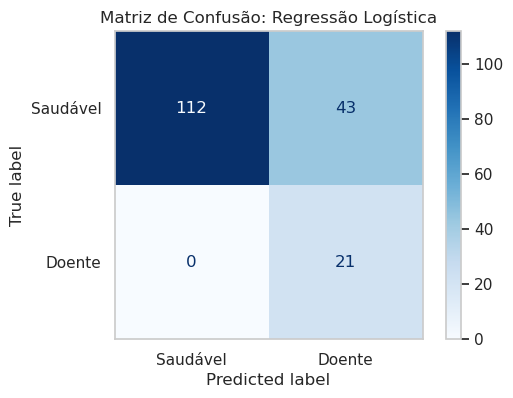

AUC-ROC: 0.947 | AUC-PR: 0.724 | Prevalência: 0.119


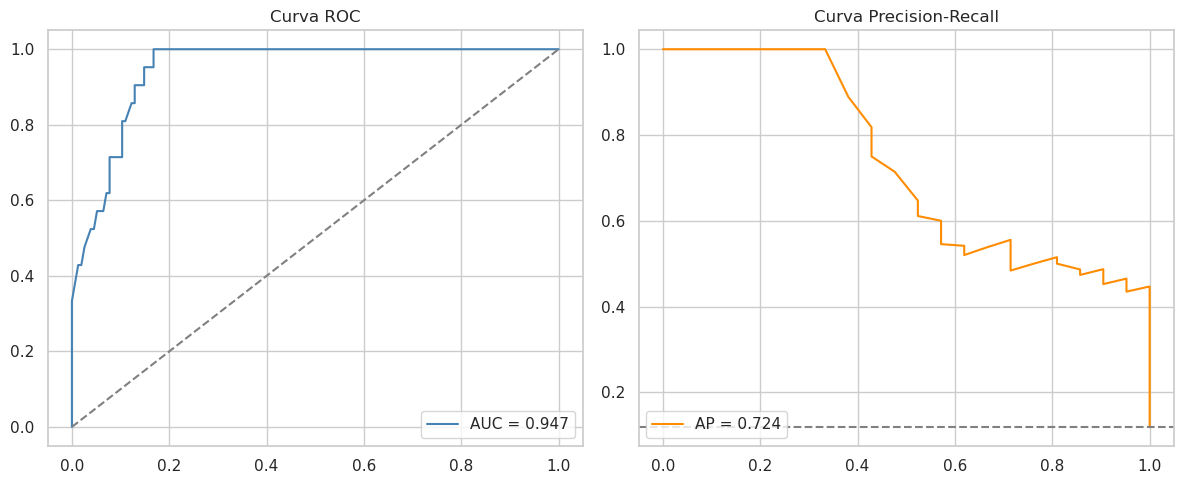


🔍 Analisando Falsos Negativos (Casos Críticos)...
Total de Falsos Negativos identificados no teste: 0

🔍 Investigando Robustez (Permutation Importance no Teste)...


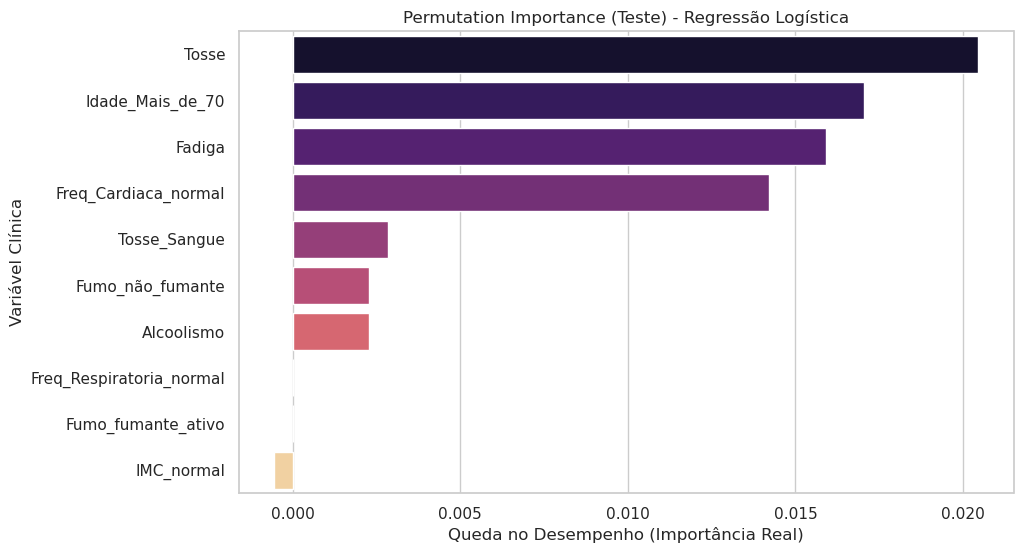

Background dataset has 408 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=408 when initializing the masker.



=== EXPLICABILIDADE COM SHAP ===

1. SHAP Summary Plot (Impacto Global das Variáveis):


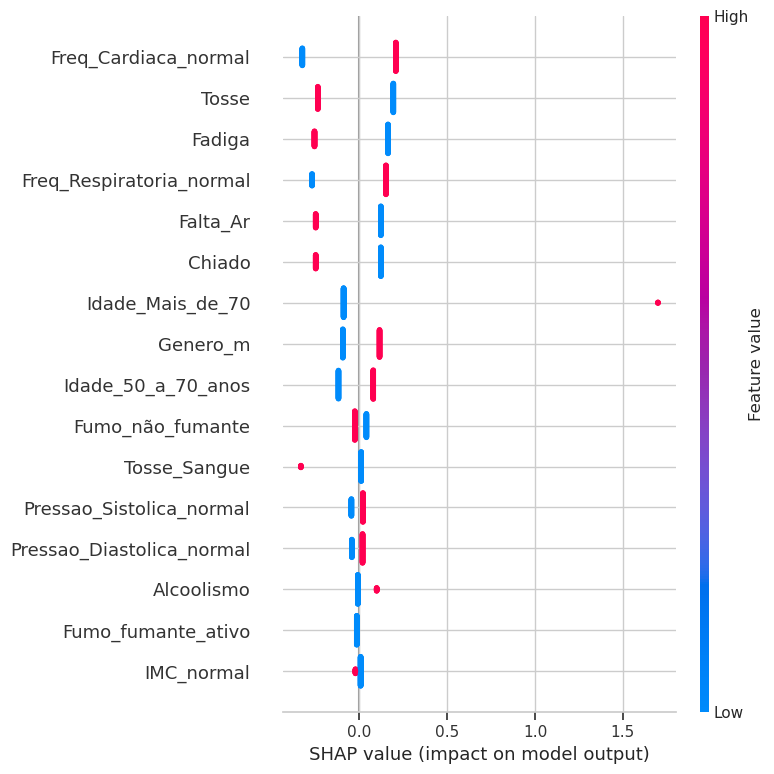


2. SHAP Waterfall Plot (Explicabilidade Local do primeiro paciente):


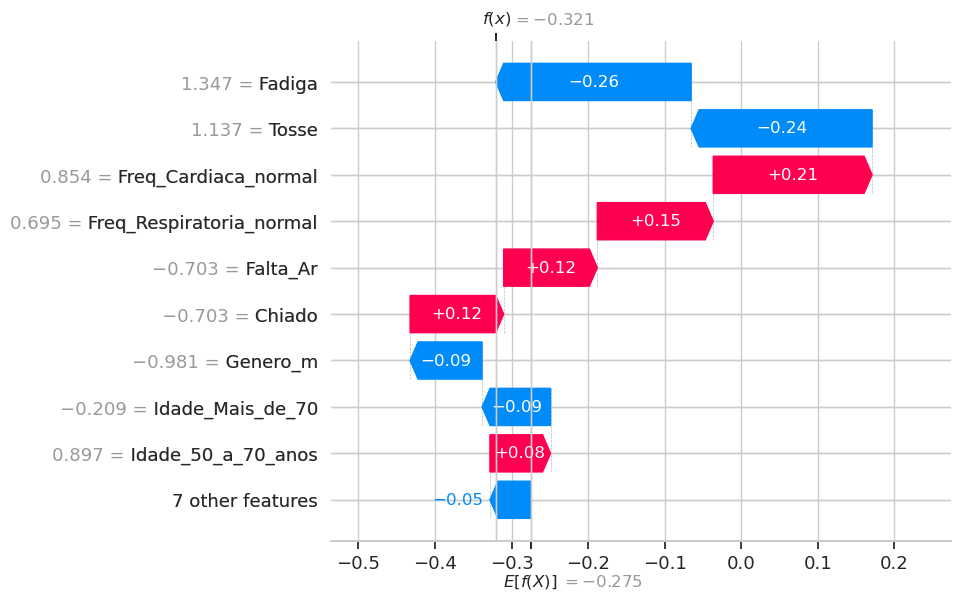

In [12]:
df = carregar_dataset("dataset_completo_v2.csv")

if df is not None:
    # Preparação
    df = filtrar_colunas(df)
    df = tratar_dados(df)
    x_treino, x_teste, y_treino, y_teste, algoritmos = preparar_dados_treino(df, "Target")
    
    # Modelagem
    modelo, nome_modelo = otimizar_e_comparar_algoritmos(x_treino, y_treino, algoritmos)
    predicao = modelo.predict(x_teste)
    
    # Avaliação de Desempenho e Erros
    gerar_relatorio_metricas(y_teste, predicao)
    gerar_matriz_confusao(y_teste, predicao, nome_modelo)
    avaliar_curvas(modelo, nome_modelo, x_teste, y_teste)
    analisar_erros(x_teste, y_teste, predicao)
    
    # Explicabilidade
    gerar_grafico_importancia(modelo, nome_modelo, x_teste, y_teste)
    aplicar_shap(modelo, x_treino, x_teste)